In [8]:
import numpy as np
from optiland import optic

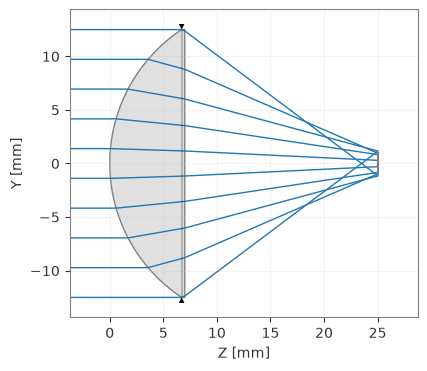

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [23]:
singlet = optic.Optic()

# define surfaces
singlet.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
singlet.surfaces.add(index=1, radius=15, thickness=7, is_stop=True, material="N-BK7")
singlet.surfaces.add(index=2, radius=np.inf, thickness=18)
singlet.surfaces.add(index=3)

# define aperture
singlet.set_aperture(aperture_type="EPD", value=25)

# define fields
singlet.fields.set_type(field_type="angle")
singlet.fields.add(y=0)

# define wavelengths
singlet.wavelengths.add(value=0.5, is_primary=True)

# draw it
singlet.draw(num_rays=10)

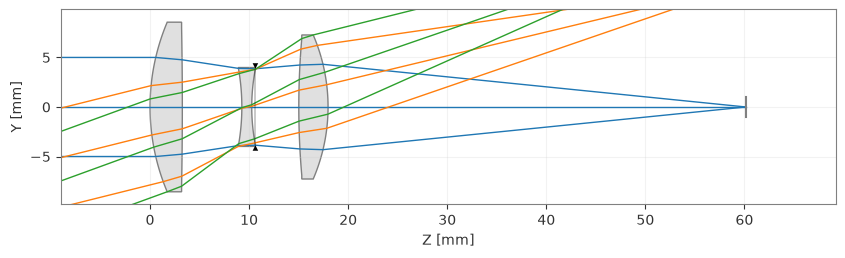

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [75]:
from optiland.samples.objectives import CookeTriplet
from optiland.prescription import Prescription

lens = CookeTriplet()
lens.draw()
#p = Prescription(lens)
#p.view()

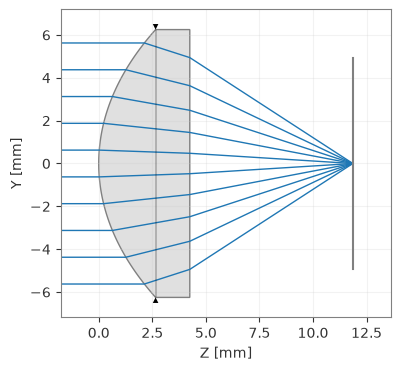

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [118]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file

new_system = load_zemax_file("D:/usere/Download/AL1210-Zemax-ZMX.zmx")
new_system.draw(num_rays=10)

#p = Prescription(new_system)
#p.view()

In [119]:
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram
from optiland.diagnostics import check_system
from optiland.optic import Optic

new_system.set_aperture(aperture_type="EPD", value=8)
new_system.wavelengths.remove(index = 0)
new_system.wavelengths.add(value = 1.55)
filed_separation = 1/17
for i in range(5):    
    new_system.fields.add(y=(i+1)*filed_separation)
new_system.updater.image_solve()

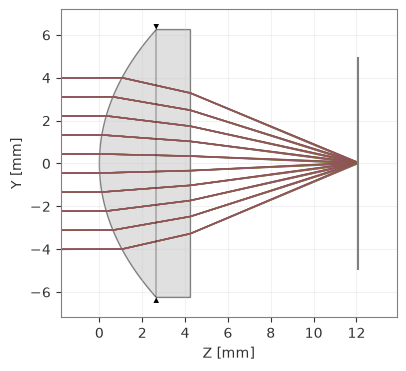

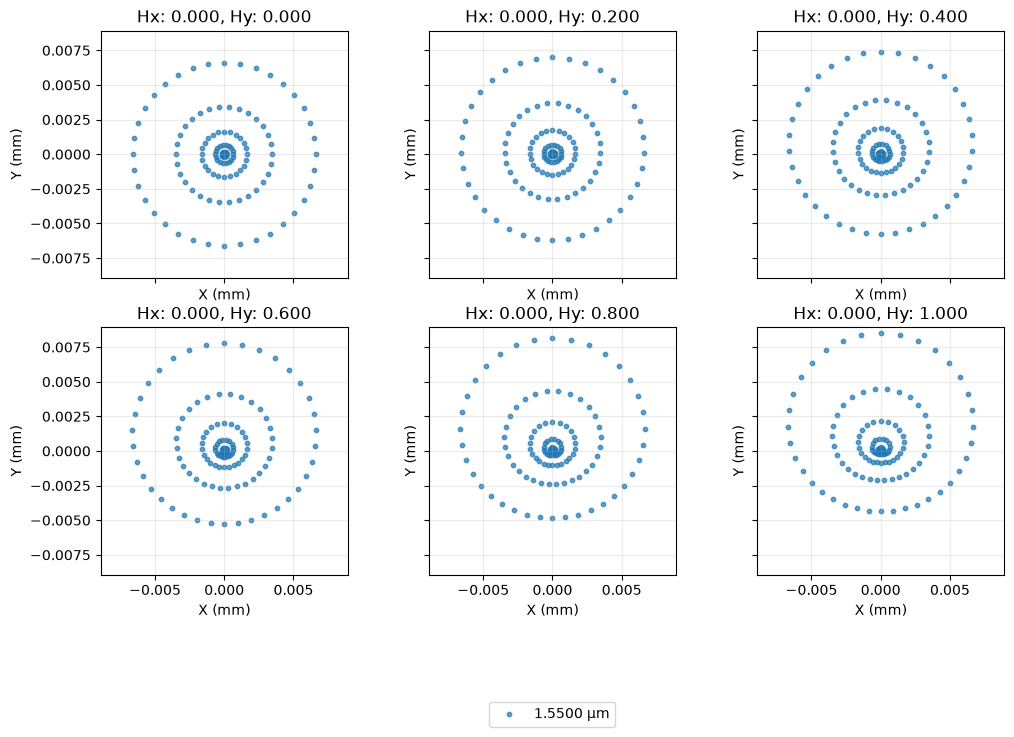

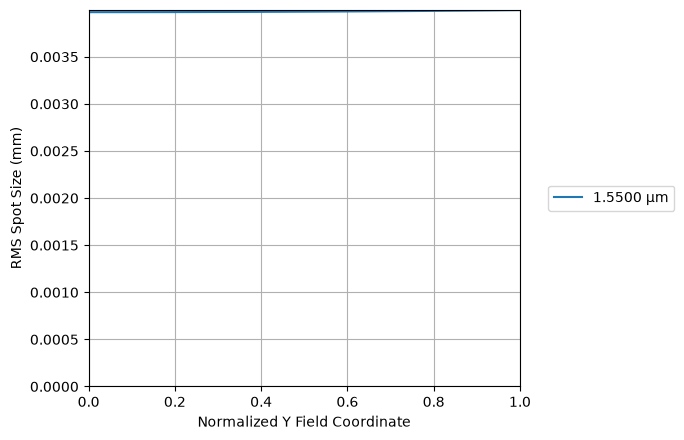

Optimized RMS spot radius by field (um):
[np.float64(0.003973213402982177)]
[np.float64(0.003973213402982177)]
[np.float64(0.003973213402982177)]
[np.float64(0.003973213402982177)]
[np.float64(0.003973213402982177)]


In [ ]:
new_system.draw(num_rays=10)
spot = SpotDiagram(new_system, num_rings = 6, fields = "all", wavelengths = 0)
spot.view()
#RayFan(new_system).view()
RmsSpotSizeVsField(new_system, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
for i in range(5):
    print(spot.rms_spot_radius())

#p = Prescription(new_system)
#p.view()

In [93]:
from optiland.optimization import OptimizationProblem, OptimizerGeneric

problem = OptimizationProblem()

problem.add_variable(new_system, "thickness", surface_number=-1)

for hy in [-1/17, 0, 1/17]:
    problem.add_operand(
            "rms_spot_size",
            target=0.0,
            weight=1.0,
            input_data={
                "optic": new_system,
                "Hx": 0.0,
                "Hy": hy,
                "num_rays": 10,
                "wavelength": 1.55,
                "surface_number": -1,  # the image surface
            },)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
print(f"image_pos: {float(new_system.surfaces[-1].geometry.cs.z):.3f} mm")

Merit function before: 0.000040
image_pos: 12.060 mm


In [90]:
OptimizerGeneric(problem).optimize(maxiter=10000)
#lens.updater.image_solve()  # optimization moved the focus; refocus the image plane

print(f"Merit function after:  {float(problem.sum_squared()):.6f}")
print(f"image_pos: {float(new_system.surfaces[-1].geometry.cs.z):.3f} mm")

d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:41: RuntimeWarning: invalid value encountered in multiply
  rays.y = rays.y + t * rays.M
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize

Merit function after:  0.000040
image_pos: 12.060 mm


d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:41: RuntimeWarning: invalid value encountered in multiply
  rays.y = rays.y + t * rays.M
d:\usere\Documents\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\propagation\homogeneous.py:40: RuntimeWarning: invalid value encountered in multiply
  rays.x = rays.x + t * rays.L
